In [11]:
%pip install numpy pandas matplotlib seaborn scikit-learn xgboost optuna plotly anywidget

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import optuna

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, roc_auc_score, precision_recall_curve,
                             average_precision_score)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
print("xgboost", xgb.__version__, "| optuna", optuna.__version__)

xgboost 3.4.1 | optuna 5.0.0


## Part 1 – Cleaned dataset, encoding and target classes 

* `Order`, `PID`: identifiers
* `Alley`, `Pool QC`, `Misc Feature`: > 90 % "NA"
* `Garage Yr Blt`: correlation 0.83 with `Year Built`
* `Garage Cars`: correlation 0.89 with `Garage Area`
* For all other categorical columns "NA" means "feature not present" (no garage, no basement etc) → replaced by the category `"None"`.
* `Lot Frontage` (truly missing, 17 %) → median of the same `Neighborhood`.
* Numeric basement/garage/veneer columns that are NA because the feature does not exist → 0.
* `Gr Liv Area > 4000`: the five outliers from L1 → removed

In [13]:
initial = pd.read_csv("AmesHousing.csv", sep="\t")
print("Initial shape:", initial.shape)

def clean(df, drop_outliers=True):
    df = df.copy()
    # 1) identifiers and columns that are almost empty
    df = df.drop(columns=["Order", "PID", "Alley", "Pool QC", "Misc Feature",
                          "Garage Yr Blt", "Garage Cars"])
    # 2) outliers identified in L1
    if drop_outliers:
        df = df[df["Gr Liv Area"] <= 4000]
    
    # Missing values
    # 3) "NA" = feature not present -> category "None"
    cat_cols = df.select_dtypes(include="object").columns
    df[cat_cols] = df[cat_cols].fillna("None")
    df["Electrical"] = df["Electrical"].replace("None", df["Electrical"].mode()[0])  # 1 truly missing value
    # 4) numeric columns
    df["Lot Frontage"] = df.groupby("Neighborhood")["Lot Frontage"].transform(lambda s: s.fillna(s.median()))
    df["Lot Frontage"] = df["Lot Frontage"].fillna(df["Lot Frontage"].median())
    num_cols = df.select_dtypes(include="number").columns.drop("SalePrice")
    df[num_cols] = df[num_cols].fillna(0)
    return df

housing = clean(initial)
print("Cleaned shape:", housing.shape, "| remaining NaN:", int(housing.isna().sum().sum()))

Initial shape: (2930, 82)
Cleaned shape: (2925, 75) | remaining NaN: 0


,class,count,percent
0,<100k,237,8.1
1,100-130k,509,17.4
2,130-180k,1036,35.4
3,180-250k,684,23.4
4,250-400k,397,13.6
5,>=400k,62,2.1


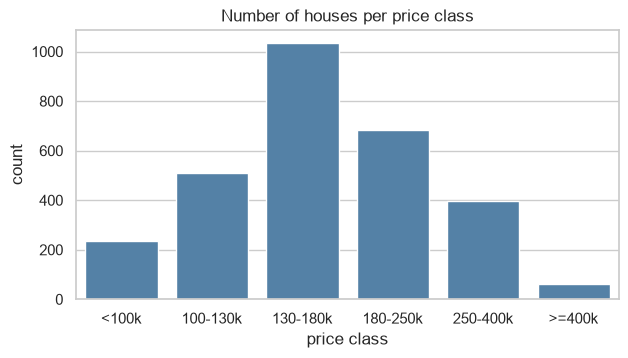

In [14]:
BINS = [0, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]
CLASS_NAMES = ["<100k", "100-130k", "130-180k", "180-250k", "250-400k", ">=400k"]

def make_target(df):
    # intervals [a, b): 100000 belongs to class 1, 400000 to class 5
    return pd.cut(df["SalePrice"], bins=BINS, right=False, labels=False).astype(int)

y_all = make_target(housing)
dist = pd.DataFrame({"class": CLASS_NAMES, "count": y_all.value_counts().sort_index().values})
dist["percent"] = (dist["count"] / len(y_all) * 100).round(1)
display(dist)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=CLASS_NAMES, y=dist["count"], color="steelblue")
plt.title("Number of houses per price class"); plt.ylabel("count"); plt.xlabel("price class")
plt.show()


**Interpretation.** The classes are imbalanced: the middle class `130-180k` contains about 35 % of the houses, whereas `>=400k` has only 62 houses (2.1 %). This is why *accuracy alone is misleading* (always predicting `130-180k` would give 35 %), why we report **macro-averaged** metrics (every class counts equally), and why stratification and class weights are tested.

In [15]:
QUAL = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_MAPS = {
    "Exter Qual": QUAL, "Exter Cond": QUAL, "Bsmt Qual": QUAL, "Bsmt Cond": QUAL,
    "Heating QC": QUAL, "Kitchen Qual": QUAL, "Fireplace Qu": QUAL,
    "Garage Qual": QUAL, "Garage Cond": QUAL,
    "Bsmt Exposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Functional": {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "Garage Finish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "Lot Shape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Land Slope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Utilities": {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},
    "Central Air": {"N": 0, "Y": 1},
}

def add_features(df):
    # combined features
    d = df.copy()
    d["TotalSF"]      = d["Total Bsmt SF"] + d["1st Flr SF"] + d["2nd Flr SF"]
    d["HouseAge"]     = d["Yr Sold"] - d["Year Built"]
    d["RemodAge"]     = d["Yr Sold"] - d["Year Remod/Add"]
    d["TotalBath"]    = d["Full Bath"] + 0.5 * d["Half Bath"] + d["Bsmt Full Bath"] + 0.5 * d["Bsmt Half Bath"]
    d["TotalPorchSF"] = d["Open Porch SF"] + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"] + d["Wood Deck SF"]
    d["IsRemodeled"]  = (d["Year Remod/Add"] != d["Year Built"]).astype(int)
    d["QualxSF"]      = d["Overall Qual"] * d["Gr Liv Area"]
    return d

def build_features(df, nominal="onehot", engineer=False, drop_corr=False):
    d = df.drop(columns=["SalePrice"]).copy()
    d["MS SubClass"] = d["MS SubClass"].astype(str) 
    if engineer:
        d = add_features(d)
    for col, mp in ORDINAL_MAPS.items():
        d[col] = d[col].map(mp).astype(float)
    nom_cols = d.select_dtypes(include="object").columns.tolist()
    if nominal == "onehot":
        d = pd.get_dummies(d, columns=nom_cols, dtype=int)
    elif nominal == "label":
        for c in nom_cols:
            d[c] = d[c].astype("category").cat.codes
    elif nominal == "native":
        for c in nom_cols:
            d[c] = d[c].astype("category")
    if drop_corr:
        num = d.select_dtypes(include="number")
        corr = num.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
        d = d.drop(columns=to_drop)
    d.columns = [str(c).replace("[", "(").replace("]", ")").replace("<", "lt") for c in d.columns]
    return d

X_all = build_features(housing)
print("Features after encoding:", X_all.shape[1])
print("Nominal columns one-hot encoded:", housing.drop(columns=["SalePrice"]).select_dtypes("object").columns.difference(list(ORDINAL_MAPS)).size + 1)
print("Ordinal columns mapped to integers:", len(ORDINAL_MAPS))
X_all.iloc[:3, :12]

Features after encoding: 236
Nominal columns one-hot encoded: 21
Ordinal columns mapped to integers: 20


,Lot Frontage,Lot Area,Lot Shape,Utilities,Land Slope,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Exter Qual,Exter Cond
0,141.0,31770,2.0,3.0,2.0,6,5,1960,1960,112.0,3.0,3.0
1,80.0,11622,3.0,3.0,2.0,5,6,1961,1961,0.0,3.0,3.0
2,81.0,14267,2.0,3.0,2.0,6,6,1958,1958,108.0,3.0,3.0


In [16]:
# base settings of the model(200 succesive decision trees etc)
BASE_PARAMS = dict(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8,
                   colsample_bytree=0.8, min_child_weight=1, gamma=0, reg_lambda=1,
                   tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)

def fit_model(params, X, y, weights=None, **kw):
    m = xgb.XGBClassifier(**params, **kw)
    m.fit(X, y, sample_weight=weights)
    return m

def scores(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, average="macro", zero_division=0),
                recall=recall_score(y_true, y_pred, average="macro", zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average="macro", zero_division=0))

#K-Fold-Cross-Validation
def cv_eval(X, y, params=BASE_PARAMS, splitter=None, weight_mode=None, return_folds=False):
    splitter = splitter or StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for tr, va in splitter.split(X, y):
        w = compute_sample_weight(weight_mode, y.iloc[tr]) if weight_mode == "balanced" else None
        if weight_mode == "sqrt":
            w = np.sqrt(compute_sample_weight("balanced", y.iloc[tr]))
        m = fit_model(params, X.iloc[tr], y.iloc[tr], w, **({"enable_categorical": True}
                      if any(str(t) == "category" for t in X.dtypes) else {}))
        r_va = scores(y.iloc[va], m.predict(X.iloc[va]))
        r_tr = scores(y.iloc[tr], m.predict(X.iloc[tr]))
        rows.append({**{f"val_{k}": v for k, v in r_va.items()}, "train_macro_f1": r_tr["macro_f1"],
                     "train_accuracy": r_tr["accuracy"]})
    df = pd.DataFrame(rows)
    return df if return_folds else df.agg(["mean", "std"]).T

def pm(series_mean, series_std, nd=3):
    return f"{series_mean:.{nd}f} ± {series_std:.{nd}f}"

## Part 2 – Train/test split 10 % vs 20 %, with and without stratification

acc_mean  acc_std  f1_mean  f1_std  train_f1  class5_in_test_min  class5_in_test_max
test_size stratified                                                                                      
10 %      False         0.7713   0.0169   0.7596  0.0169    0.9932                   2                  11
          True          0.7706   0.0298   0.7558  0.0525    0.9942                   6                   6
20 %      False         0.7631   0.0218   0.7416  0.0175    0.9951                   7                  16
          True          0.7754   0.0140   0.7625  0.0255    0.9954                  12                  12

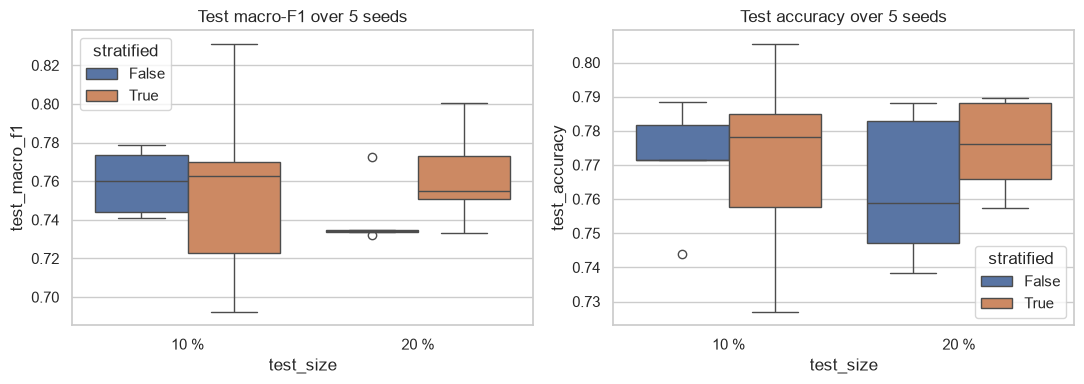

In [17]:
rows = []
for test_size in [0.10, 0.20]:
    for strat in [False, True]:
        for seed in range(5):
            Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=test_size, random_state=seed,
                                                  stratify=y_all if strat else None)
            m = fit_model(BASE_PARAMS, Xtr, ytr)
            te, tr = scores(yte, m.predict(Xte)), scores(ytr, m.predict(Xtr))
            rows.append(dict(test_size=f"{int(test_size*100)} %", stratified=strat, seed=seed,
                             test_accuracy=te["accuracy"], test_macro_f1=te["macro_f1"],
                             train_macro_f1=tr["macro_f1"], n_test=len(yte),
                             test_n_class5=int((yte == 5).sum())))
split_res = pd.DataFrame(rows)
summary = split_res.groupby(["test_size", "stratified"]).agg(
    acc_mean=("test_accuracy", "mean"), acc_std=("test_accuracy", "std"),
    f1_mean=("test_macro_f1", "mean"), f1_std=("test_macro_f1", "std"),
    train_f1=("train_macro_f1", "mean"),
    class5_in_test_min=("test_n_class5", "min"), class5_in_test_max=("test_n_class5", "max")).round(4)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=split_res, x="test_size", y="test_macro_f1", hue="stratified", ax=ax[0])
ax[0].set_title("Test macro-F1 over 5 seeds")
sns.boxplot(data=split_res, x="test_size", y="test_accuracy", hue="stratified", ax=ax[1])
ax[1].set_title("Test accuracy over 5 seeds")
plt.tight_layout(); plt.show()

* **Overall Performance**: All four configurations reach a very similar test performance (macro-F1 ≈ 0.75–0.76, accuracy ≈ 0.77–0.78).
* **The Role of Stratification**: Stratification makes our test set stable and consistent. With stratification, the rare >=400k class always shows up the exact same number of times—6 times for a 10% test or 12 times for a 20% test. Without it, the count bounces around randomly between 2 and 11 (for 10%) or 7 and 16 (for 20%). If the test randomly gets only 2 rare houses, the score for that class becomes pretty much useless. The highest average macro-F1 was achieved using the 20% stratified setup (0.760). 
* **10% vs. 20% Test**: A 10% test set (≈ 293 houses) leaves more data for training (less bias), but the estimate is noisier (e.g., std of macro-F1 is 0.052 with stratification, with only 6 rare houses in the test set). A 20% test set gives a more reliable estimate and costs only a little training data.
* **Overfitting Issue**: The training macro-F1 is ≈ 0.99 while the test macro-F1 is ≈ 0.75: the model fits the training data almost perfectly 

## Part 3 – k-fold cross validation (k = 5 and k = 10), bias–variance trade-off

,k,splitter,val_accuracy,val_macro_f1,train_macro_f1,gap_train_minus_val,f1_range_over_folds
0,5,KFold,0.757 ± 0.020,0.746 ± 0.014,0.995,0.250,0.734 – 0.762
1,5,StratifiedKFold,0.769 ± 0.016,0.742 ± 0.025,0.995,0.253,0.711 – 0.779
2,10,KFold,0.766 ± 0.021,0.756 ± 0.016,0.993,0.237,0.730 – 0.781
3,10,StratifiedKFold,0.772 ± 0.028,0.755 ± 0.035,0.993,0.238,0.691 – 0.803


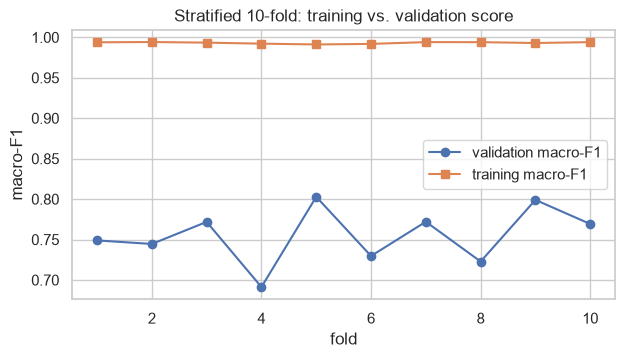

In [18]:
rows = []
for k in [5, 10]:
    for name, SplitCls in [("KFold", KFold), ("StratifiedKFold", StratifiedKFold)]:
        folds = cv_eval(X_all, y_all, BASE_PARAMS, SplitCls(k, shuffle=True, random_state=RANDOM_STATE), return_folds=True)
        rows.append(dict(k=k, splitter=name,
                         val_accuracy=pm(folds.val_accuracy.mean(), folds.val_accuracy.std()),
                         val_macro_f1=pm(folds.val_macro_f1.mean(), folds.val_macro_f1.std()),
                         train_macro_f1=round(folds.train_macro_f1.mean(), 3),
                         gap_train_minus_val=round(folds.train_macro_f1.mean() - folds.val_macro_f1.mean(), 3),
                         f1_range_over_folds=f"{folds.val_macro_f1.min():.3f} – {folds.val_macro_f1.max():.3f}"))
        if k == 10 and name == "StratifiedKFold":
            fold_plot = folds
cv_table = pd.DataFrame(rows)
display(cv_table)

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 11), fold_plot.val_macro_f1, "o-", label="validation macro-F1")
plt.plot(range(1, 11), fold_plot.train_macro_f1, "s-", label="training macro-F1")
plt.xlabel("fold"); plt.ylabel("macro-F1"); plt.title("Stratified 10-fold: training vs. validation score")
plt.legend(); plt.show()

* **Cross-Validation**: Instead of doing just one random split, cross-validation tests every house on validation once. This gives us a much more reliable average and standard deviation. Our validation macro-F1 ends up around 0.74–0.76, which matches what we saw in the previous split experiments.   
* **k = 5 vs. k = 10**: When we use $k = 10$, the model trains on 90% of the data instead of 80%, so the score is slightly higher and less pessimistic (lower bias). However, because each validation chunk is smaller (~293 houses with only about 6 rare houses), the scores bounce around a lot more between folds (ranging from 0.6961 to 0.803), meaning higher variance. Plus, $k = 10$ takes twice as long to compute.   
* **KFold vs. StratifiedKFold**: The average scores are pretty much the same (within one standard deviation). Still, stratification is the safer and better choice because it makes sure the rare class is always properly balanced in every fold.   
* **Bias-Variance Trade-off**: There is a huge gap here—our training macro-F1 is around 0.99, while validation drops to about 0.75. This means the model has very low bias but high variance, basically memorizing the training data instead of generalizing (overfitting). To fix this, we'd normally need more data, stronger regularization, or simpler trees (which we'll test in Part 7).

**Fixed split strategy**: From now on, we stick to a single, fixed 80% / 20% stratified split so that the test set remains completely untouched until the final evaluation. All model tuning, hyperparameter choices, and Optuna searches will be done exclusively using 5-fold stratified cross-validation on the training portion only, keeping our test results completely honest and unbiased.

In [19]:
idx_train, idx_test = train_test_split(housing.index, test_size=0.20, random_state=RANDOM_STATE,
                                       stratify=y_all)
y_train, y_test = y_all.loc[idx_train], y_all.loc[idx_test]
X_train, X_test = X_all.loc[idx_train], X_all.loc[idx_test]
print("train:", X_train.shape, "| test:", X_test.shape)
print(pd.DataFrame({"train %": (y_train.value_counts(normalize=True).sort_index()*100).round(1),
                    "test %": (y_test.value_counts(normalize=True).sort_index()*100).round(1)}))

train: (2340, 236) | test: (585, 236)
           train %  test %
SalePrice                 
0              8.1     8.2
1             17.4    17.4
2             35.4    35.4
3             23.4    23.4
4             13.6    13.5
5              2.1     2.1


## Part 4 - Trees and Feature Importance

In this section, we investigate how the XGBoost model makes predictions by examining individual decision trees and analyzing feature importance.

Since the task is a multiclass classification problem, the model assigns each house to one of six price categories based on its characteristics.

The analysis consists of the following steps:

1. **Early stopping:** We train the model with a validation set and use early stopping to determine when additional boosting iterations no longer improve validation performance.
2. **Decision tree visualization:** We visualize the first tree to understand how the model splits the feature space into different regions.
3. **Feature importance:** We examine feature importance using different measures, such as gain and weight, to identify the features that contribute most to the model's predictions.

These analyses help us understand the model's structure and identify the housing characteristics that are most influential in the classification process.


In [20]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Fit:", X_fit.shape)
print("Validation:", X_val.shape)

Fit: (1872, 236)
Validation: (468, 236)


In [21]:

# 2. Antrenare cu Early Stopping

EARLY_PARAMS = {
    **BASE_PARAMS,
    "n_estimators": 1000,
    "learning_rate": 0.05,
    "max_depth": 4,
    "early_stopping_rounds": 30,
    "eval_metric": "mlogloss"
}

# Cream modelul direct, fara functia fit_model() a colegei
model = xgb.XGBClassifier(**EARLY_PARAMS)

# Antrenam modelul cu setul de validare
model.fit(
    X_fit,
    y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Best iteration:", model.best_iteration)
print("Best validation score:", model.best_score)


Best iteration: 235
Best validation score: 0.6001346223817493


In [22]:
import shutil
print(shutil.which("dot"))

None


In [23]:

%pip install graphviz


  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



**4.1 Decision Tree Visualization**

The first decision tree illustrates how XGBoost uses feature-based splitting rules to distinguish between observations. Each split evaluates a condition on a feature, while the resulting branches lead to further decisions or leaf nodes.

Visualizing the tree provides insight into the model's decision-making process. However, a single tree does not represent the complete model, because XGBoost combines the predictions of multiple trees.

ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

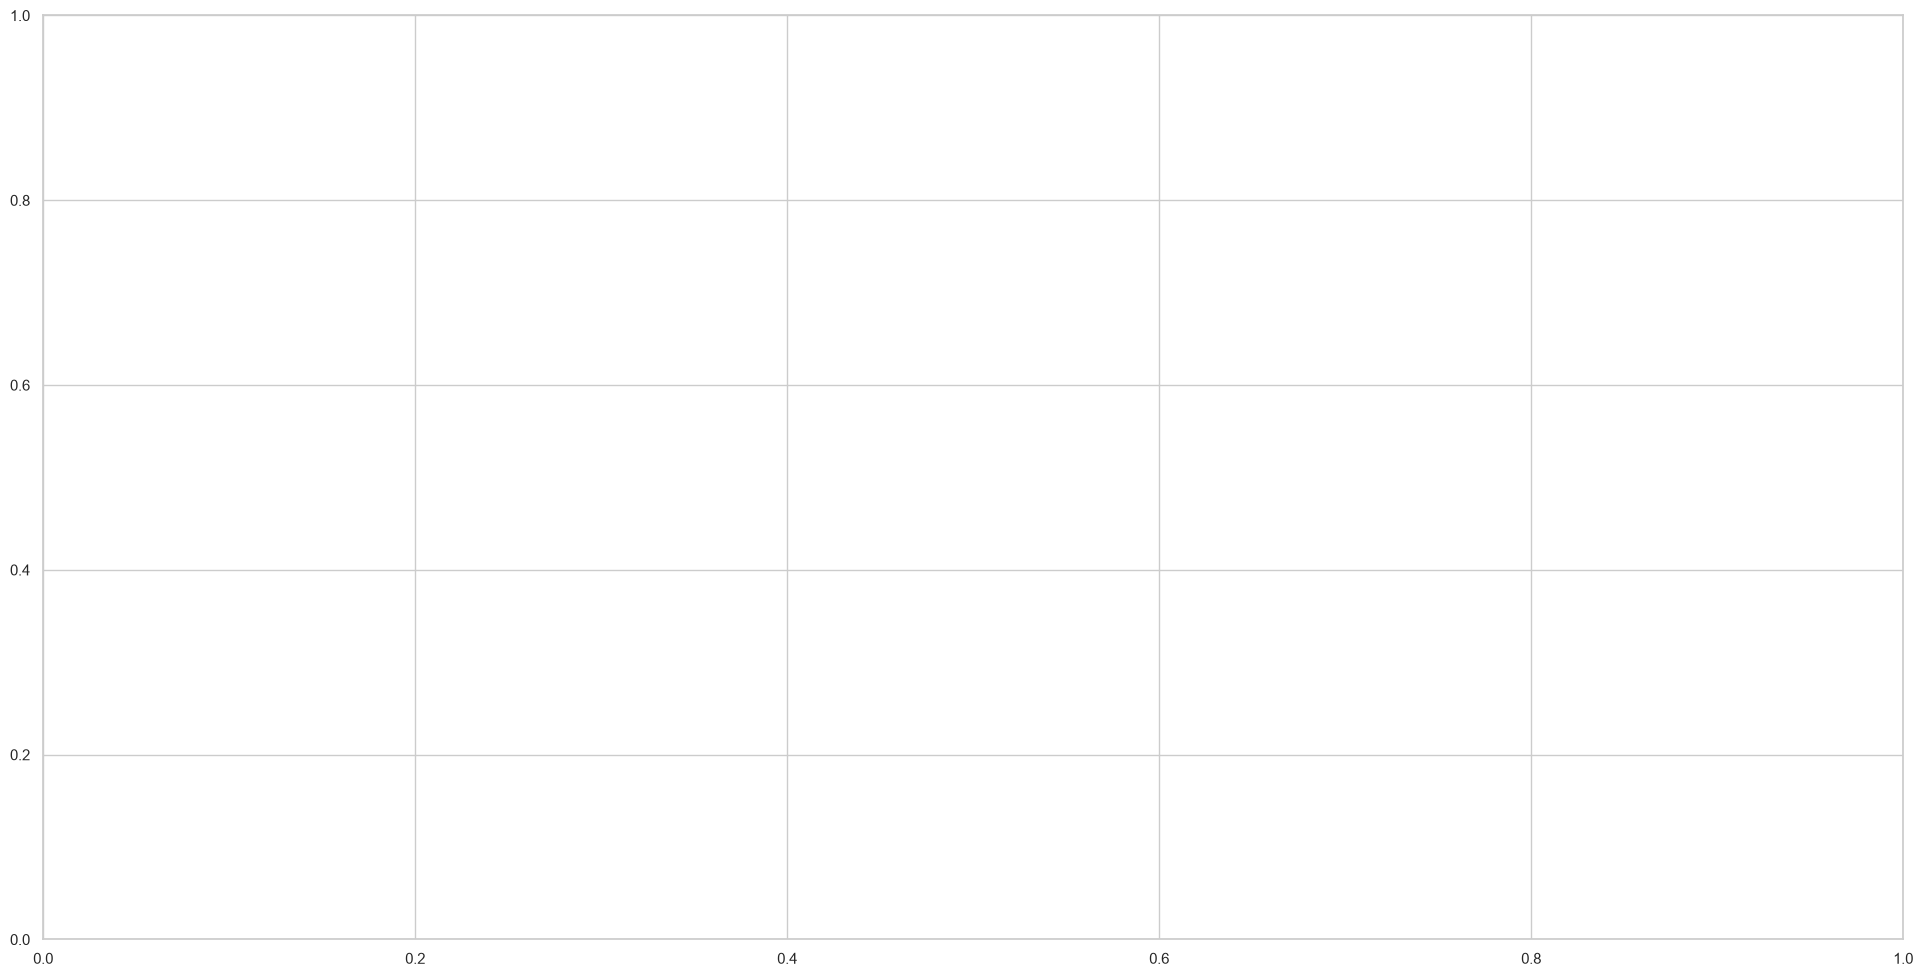

In [27]:
fig, ax = plt.subplots(figsize=(24, 12))

xgb.plot_tree(
    model,
    num_trees=0,
    rankdir="LR",
    ax=ax
)

plt.title("First XGBoost tree")
plt.show()

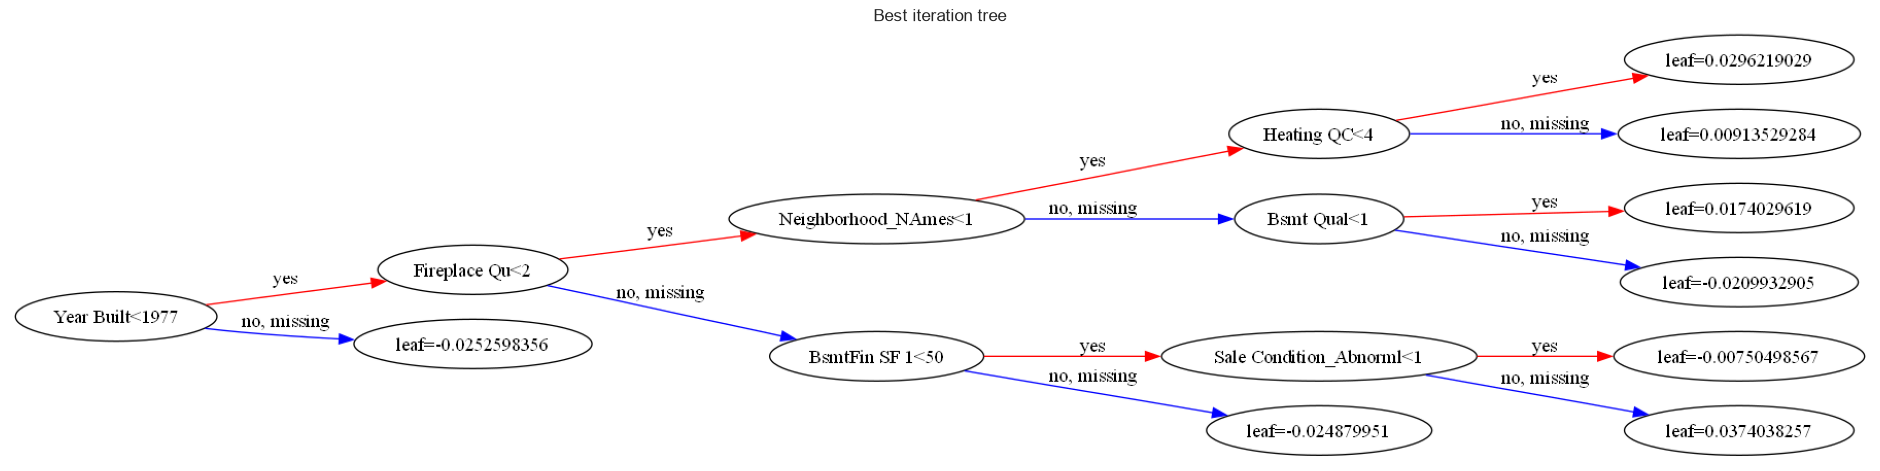

In [ ]:
fig, ax = plt.subplots(figsize=(24, 12))

xgb.plot_tree(
    model,
    num_trees=model.best_iteration,
    rankdir="LR",
    ax=ax
)

plt.title("Best iteration tree")
plt.show()


**4.2 Feature Importance Analysis**

Feature importance helps identify which variables contribute most to the model's predictions.

We analyze two importance measures:

- **Gain:** Measures the improvement in the model's objective function achieved by splits using a particular feature.
- **Weight:** Measures how frequently a feature is used to split the data across the trees.

Comparing these measures provides complementary information. A feature may be used frequently without producing the largest improvement in predictive performance.

Feature importance describes the model's use of the available variables; it does not establish causal relationships between housing characteristics and sale prices.


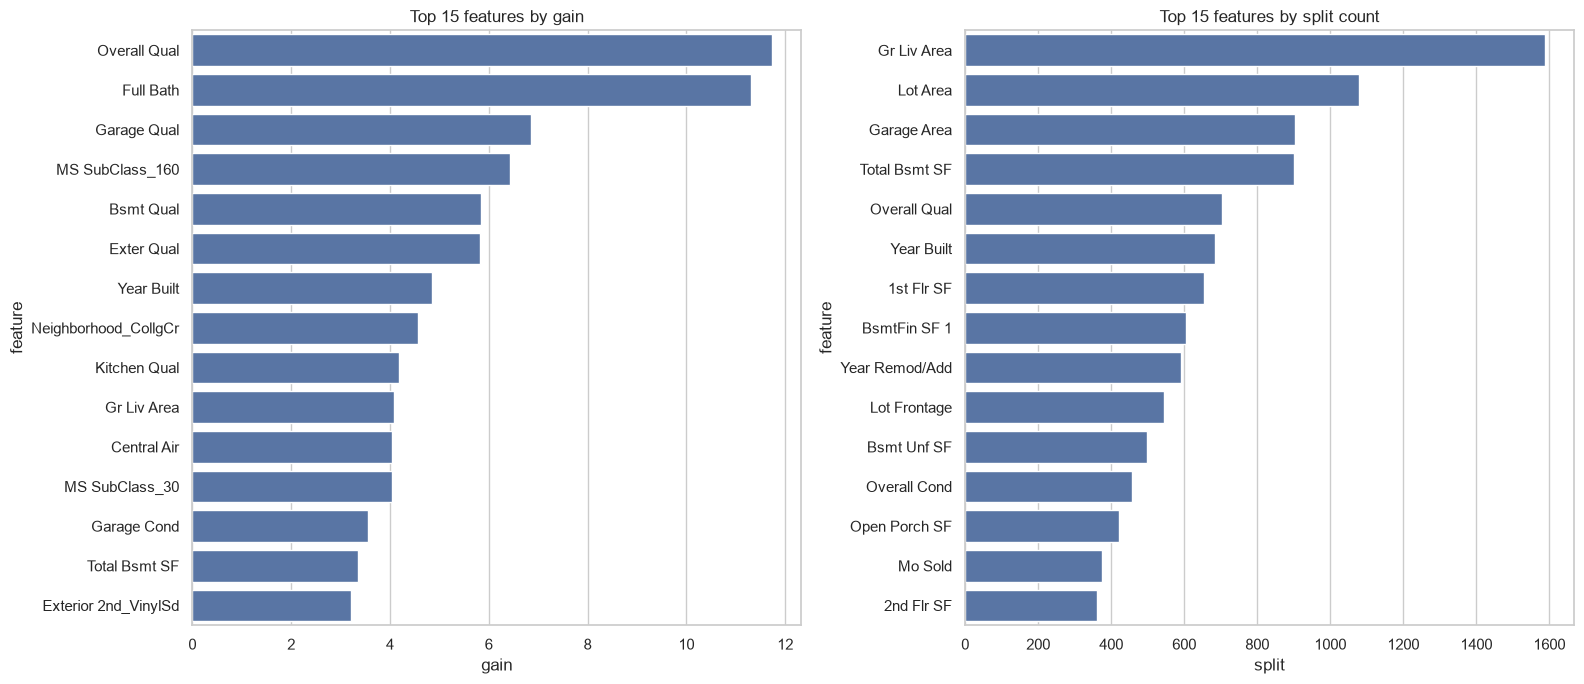

In [ ]:
booster = model.get_booster()

gain = booster.get_score(importance_type="gain")
weight = booster.get_score(importance_type="weight")

importance = pd.DataFrame({
    "feature": X_fit.columns,
    "gain": [gain.get(c, 0) for c in X_fit.columns],
    "split": [weight.get(c, 0) for c in X_fit.columns]
})

top_gain = importance.sort_values("gain", ascending=False).head(15)
top_split = importance.sort_values("split", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=top_gain, x="gain", y="feature", ax=axes[0])
axes[0].set_title("Top 15 features by gain")

sns.barplot(data=top_split, x="split", y="feature", ax=axes[1])
axes[1].set_title("Top 15 features by split count")

plt.tight_layout()
plt.show()

## Part 5 - Metrics and Curves


In this section, we evaluate the performance of the XGBoost classifier on the test set, which was not used for model training or hyperparameter selection.

The target variable, SalePrice, has been transformed into six price categories. Therefore, model performance must be evaluated as a multiclass classification task.

We use several complementary evaluation metrics:

- **Accuracy:** The proportion of correctly classified observations.
- **Precision (macro):** The average precision across all classes, giving each class equal weight.
- **Recall (macro):** The average recall across all classes, giving each class equal weight.
- **F1-score (macro):** The average F1-score across all classes, balancing precision and recall.
- **Confusion matrix:** Shows the distribution of correct predictions and classification errors across the six classes.

Using multiple metrics provides a more complete assessment than accuracy alone, particularly when the price categories contain different numbers of observations.


In [ ]:
FINAL_PARAMS = {
    **BASE_PARAMS,
    "n_estimators": model.best_iteration + 1,
    "eval_metric": "mlogloss"
}

final_model = fit_model(
    FINAL_PARAMS,
    X_train,
    y_train
)

In [ ]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4, 5],
    target_names=CLASS_NAMES,
    zero_division=0
))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro-F1:", f1_score(y_test, y_pred, average="macro"))

              precision    recall  f1-score   support

       <100k       0.76      0.65      0.70        48
    100-130k       0.72      0.70      0.71       102
    130-180k       0.77      0.84      0.81       207
    180-250k       0.78      0.74      0.76       137
    250-400k       0.78      0.82      0.80        79
      >=400k       0.86      0.50      0.63        12

    accuracy                           0.77       585
   macro avg       0.78      0.71      0.73       585
weighted avg       0.77      0.77      0.76       585

Accuracy: 0.7658119658119659
Macro-F1: 0.7332091368362065



**5.1 Confusion Matrix**

The confusion matrix compares the actual price categories with the categories predicted by the model.

The diagonal entries represent correct classifications, while the off-diagonal entries represent misclassifications. By examining these errors, we can determine which price categories are most frequently confused with one another.

This analysis is particularly useful for identifying whether the model has difficulty distinguishing between neighboring price categories or between categories with substantially different prices.


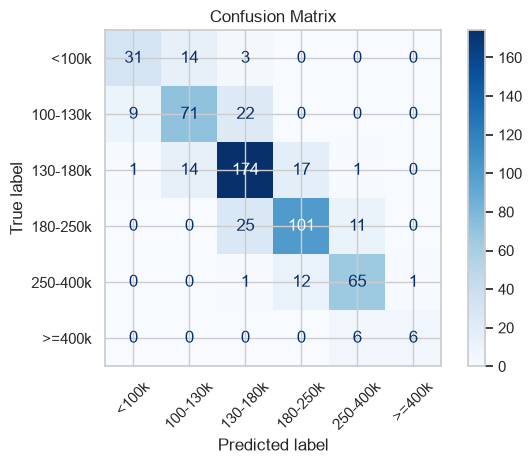

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3, 4, 5])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


**5.3 ROC and Precision–Recall Curves**

To further evaluate the XGBoost classifier, we analyze ROC and Precision–Recall curves using a one-vs-rest approach for the six price categories.

The predicted probabilities (`y_prob`) are used to evaluate how well the model distinguishes each class from all other classes across different classification thresholds.

- **ROC curve:** Shows the relationship between the True Positive Rate and the False Positive Rate at different thresholds. The Area Under the Curve (AUC) summarizes the model's ability to distinguish a given class from the remaining classes.
- **Precision–Recall curve:** Illustrates the trade-off between precision and recall at different thresholds. This curve is particularly useful for examining the performance of individual classes when their representation in the dataset differs.

Each class is evaluated separately, allowing us to identify differences in the model's ability to distinguish between the six price categories.

These curves complement accuracy, precision, recall, F1-score, and the confusion matrix by providing a threshold-independent view of classification performance.


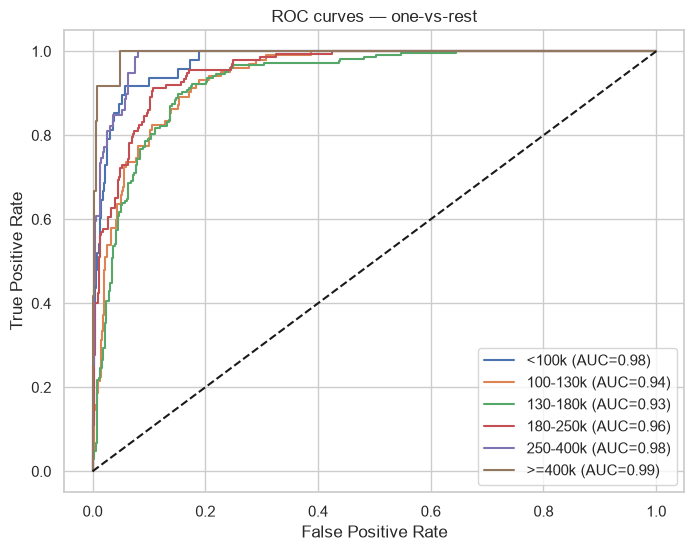

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve

classes = [0, 1, 2, 3, 4, 5]
y_test_bin = label_binarize(y_test, classes=classes)

fig, ax = plt.subplots(figsize=(8, 6))

for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.2f})")

ax.plot([0, 1], [0, 1], "k--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves — one-vs-rest")
ax.legend()
plt.show()

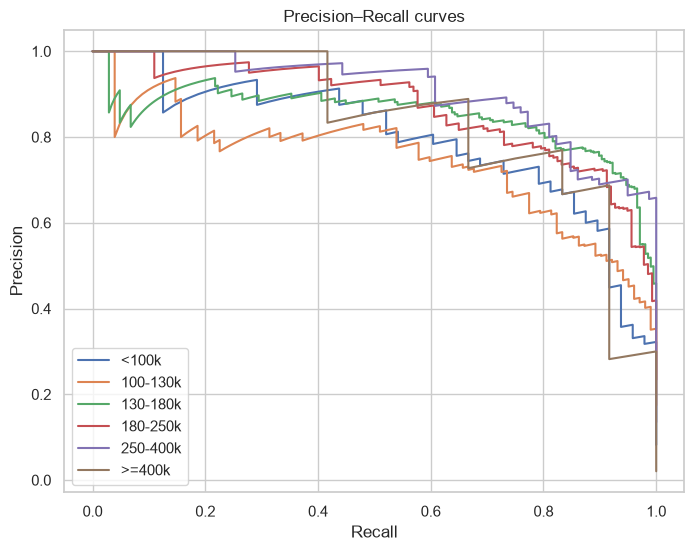

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

for i, name in enumerate(CLASS_NAMES):
    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )
    ax.plot(recall, precision, label=name)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall curves")
ax.legend()
plt.show()

## Part 6 – Data-preparation strategies and class imbalance

,strategy,n_features,val_macro_f1,val_accuracy,train_macro_f1
0,S1 one-hot + ordinal (baseline),236,0.750 ± 0.024,0.758 ± 0.010,0.998
1,S2 label-encoded nominal,74,0.749 ± 0.027,0.758 ± 0.018,0.999
2,S3 native categorical,74,0.736 ± 0.031,0.752 ± 0.020,0.999
3,S4 S1 + engineered features,243,0.748 ± 0.015,0.756 ± 0.012,0.999
4,S5 S4 - correlated features,227,0.751 ± 0.012,0.761 ± 0.007,0.999
5,S6 S1 with outliers in train,237,0.736 ± 0.024,0.755 ± 0.019,0.998


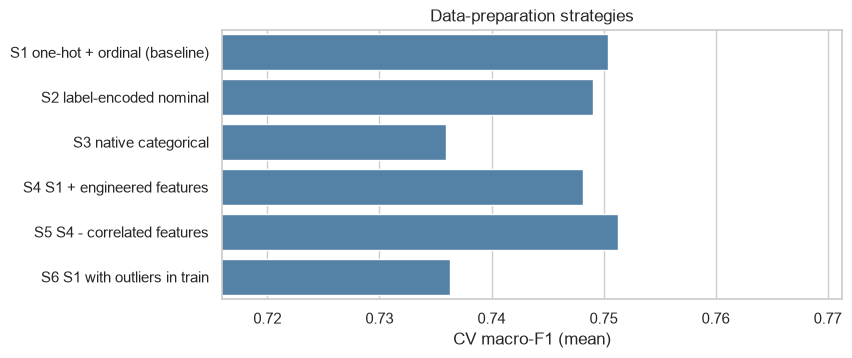

In [26]:
def subset(Xdf, idx):
    return Xdf.loc[idx]

strategies = {
    "S1 one-hot + ordinal (baseline)": build_features(housing, "onehot"),
    "S2 label-encoded nominal":        build_features(housing, "label"),
    "S3 native categorical":           build_features(housing, "native"),
    "S4 S1 + engineered features":     build_features(housing, "onehot", engineer=True),
    "S5 S4 - correlated features":     build_features(housing, "onehot", engineer=True, drop_corr=True),
}
rows = []
for name, Xs in strategies.items():
    r = cv_eval(subset(Xs, idx_train), y_train)
    rows.append(dict(strategy=name, n_features=Xs.shape[1],
                     val_macro_f1=pm(r.loc["val_macro_f1", "mean"], r.loc["val_macro_f1", "std"]),
                     val_accuracy=pm(r.loc["val_accuracy", "mean"], r.loc["val_accuracy", "std"]),
                     train_macro_f1=round(r.loc["train_macro_f1", "mean"], 3),
                     _f1=r.loc["val_macro_f1", "mean"]))

full = clean(initial, drop_outliers=False)
extra_idx = full.index.difference(housing.index)
y_full = make_target(full)
X_s6 = build_features(full, "onehot")
idx_s6 = idx_train.union(extra_idx)
r = cv_eval(X_s6.loc[idx_s6], y_full.loc[idx_s6])
rows.append(dict(strategy="S6 S1 with outliers in train", n_features=X_s6.shape[1],
                 val_macro_f1=pm(r.loc["val_macro_f1", "mean"], r.loc["val_macro_f1", "std"]),
                 val_accuracy=pm(r.loc["val_accuracy", "mean"], r.loc["val_accuracy", "std"]),
                 train_macro_f1=round(r.loc["train_macro_f1", "mean"], 3), _f1=r.loc["val_macro_f1", "mean"]))

strat_table = pd.DataFrame(rows)
display(strat_table.drop(columns="_f1"))
plt.figure(figsize=(8, 3.5))
sns.barplot(y=strat_table.strategy, x=strat_table._f1, color="steelblue")
plt.xlim(strat_table._f1.min() - 0.02, strat_table._f1.max() + 0.02)
plt.xlabel("CV macro-F1 (mean)"); plt.ylabel(""); plt.title("Data-preparation strategies"); plt.show()

* **Overall Comparison**: All strategies score pretty close to each other, with macro-F1 values sitting between 0.736 and 0.751. Since the standard deviations across folds (0.010–0.020) are bigger than the actual differences between them, no preparation strategy is clearly better. That in itself is a finding: tree models handle different encodings very well.

* **S2 vs. S1 & S3**: Label-encoding the nominal features (74 features) works just as well as one-hot encoding (236 features), but it trains faster and keeps the trees more compact. For trees, that random integer order is not an issue since they can isolate categories through multiple splits. S3 (native categories) hits the same average performance, but comes with the highest variance (0.031).

* **S4 (Engineered Features)**: Adding combined features like TotalSF or HouseAge changes very little because tree models can figure those combinations out on their own using successive splits on 1st Flr SF, 2nd Flr SF, Total Bsmt SF, and Year Built. Still, they are cheap to add and help keep the model's effective depth smaller.

* **S5 (Feature Pruning)**: Dropping highly correlated features (16 columns fewer than S4) gave the best average score (0.761) and the lowest variance (0.012) without losing any information. Because of this, we use S5 for the following experiments—noting that its advantage is within the noise margin.

* **S6 (Outliers)**: Keeping those five outliers in the training folds gives the lowest macro-F1 (0.736), showing no improvement. The effect is small since they are rare, but we keep them removed since three of them are non-standard Partial sales.

* **Overfitting Note**: The training macro-F1 stays around 1.0 across every strategy, proving that the overfitting does not depend on the encoding.

Best preparation strategy so far: S5 S4 - correlated features


,weighting,val_macro_f1,val_accuracy,val_macro_recall,train_macro_f1
0,None,0.751 ± 0.012,0.761 ± 0.007,0.730,0.999
1,sqrt,0.754 ± 0.016,0.756 ± 0.010,0.734,0.997
2,balanced,0.749 ± 0.022,0.750 ± 0.022,0.738,0.993


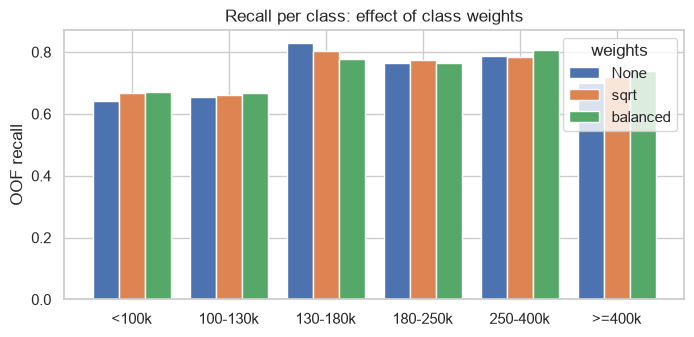

In [28]:
BEST_STRATEGY_NAME = strat_table.iloc[:5].sort_values("_f1", ascending=False).iloc[0]["strategy"] 
print("Best preparation strategy so far:", BEST_STRATEGY_NAME)
X_best_all = strategies.get(BEST_STRATEGY_NAME, X_all)
Xb_train = X_best_all.loc[idx_train]

rows = []
for mode in [None, "sqrt", "balanced"]:
    r = cv_eval(Xb_train, y_train, weight_mode=mode)
    rows.append(dict(weighting=str(mode),
                     val_macro_f1=pm(r.loc["val_macro_f1", "mean"], r.loc["val_macro_f1", "std"]),
                     val_accuracy=pm(r.loc["val_accuracy", "mean"], r.loc["val_accuracy", "std"]),
                     val_macro_recall=round(r.loc["val_recall", "mean"], 3),
                     train_macro_f1=round(r.loc["train_macro_f1", "mean"], 3)))
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(8, 3.5))
width = 0.27
for j, mode in enumerate([None, "sqrt", "balanced"]):
    pr = np.zeros(len(y_train), dtype=int)
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(Xb_train, y_train):
        w = None if mode is None else (compute_sample_weight("balanced", y_train.iloc[tr]) if mode == "balanced"
                                       else np.sqrt(compute_sample_weight("balanced", y_train.iloc[tr])))
        pr[va] = fit_model(BASE_PARAMS, Xb_train.iloc[tr], y_train.iloc[tr], w).predict(Xb_train.iloc[va])
    ax.bar(np.arange(6) + (j - 1) * width, recall_score(y_train, pr, average=None), width, label=str(mode))
ax.set_xticks(range(6)); ax.set_xticklabels(CLASS_NAMES); ax.set_ylabel("OOF recall")
ax.set_title("Recall per class: effect of class weights"); ax.legend(title="weights"); plt.show()

* Class weights ("cost-sensitive learning", one of the methods for imbalanced classes) give every sample of class c a specific weight based on its frequency.

* With sqrt weights the macro-F1 slightly rises from 0.751 to 0.754 and the macro-recall from 0.730 to 0.734 (while accuracy slightly drops from 0.761 to 0.756). On the other hand, balanced weights yield a macro-F1 of 0.749 and accuracy of 0.750, though macro-recall improves further to 0.738 as the model shifts focus towards the rare classes (see recall per class in the plot).

* The differences between the configurations are within the standard deviation ranges, so they do not prove a statistically significant benefit; as expected, the effect is modest and mainly visible in recall rather than accuracy. As an alternative to re-weighting, threshold adaptation can achieve a similar effect after training.